In [19]:
import matplotlib.pyplot as plt

In [20]:
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

UPI Fraud Detection Using Machine Learning


In [21]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings('ignore', category=FutureWarning)
ROOT = Path.cwd()
if not (ROOT / 'app').exists() and (ROOT.parent / 'app').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
%matplotlib inline
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score
from app.model import DATA_PATH, MODEL_PATH, OUTPUT_DIR, train_model, load_model
sns.set_theme(style='whitegrid', palette='deep')
print('Root:', ROOT, '| dataset exists:', DATA_PATH.exists())
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)

Root: d:\UPI | dataset exists: True
Python: 3.12.0 | pandas: 2.3.2


In [22]:
df = pd.read_csv(DATA_PATH)
target = 'is_fraud'
identifier_and_time = ['transaction id','timestamp','sender_upi_id','receiver_upi_id']
full_model_features = [c for c in df if c not in [target,*identifier_and_time]]
print(f'{len(df):,} rows × {df.shape[1]} columns; {df.memory_usage(deep=True).sum()/1024**2:.1f} MiB in memory')
display(pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique(dropna=True)}))
if df[target].isna().any() or set(pd.to_numeric(df[target],errors='raise').unique()) != {0,1}:
    raise ValueError('Expected complete binary is_fraud labels encoded 0/1.')
field_roles = [('transaction id','record identifier','excluded'),('timestamp','time string','excluded from model; EDA only'),
('transaction type','payment category','candidate'),('merchant_category','merchant category','candidate'),
('amount (INR)','amount','candidate; audit against score'),('transaction_status','status','candidate'),
('sender_age_group','sender age band','candidate'),('receiver_age_group','receiver age band','candidate'),
('sender_state','state label','candidate'),('sender_bank','sender bank','candidate'),('receiver_bank','receiver bank','candidate'),
('device_type','device category','candidate'),('network_type','network category','candidate'),
('hour_of_day','hour number','candidate'),('day_of_week','weekday label','candidate'),('is_weekend','weekend indicator','candidate'),
('sender_upi_id','account-like identifier','excluded'),('receiver_upi_id','account-like identifier','excluded'),
('risk_score','precomputed score; semantics/timing unknown','candidate; investigate'),('is_fraud','supplied binary label','target')]
feature_inventory=pd.DataFrame(field_roles,columns=['column','provisional interpretation','role'])
display(feature_inventory)
print(f'Candidate feature count: {len(full_model_features)} → {full_model_features}')

250,000 rows × 20 columns; 215.8 MiB in memory


,dtype,missing,unique
transaction id,object,0,250000
timestamp,object,0,248610
transaction type,object,0,4
merchant_category,object,0,10
amount (INR),int64,0,10355
transaction_status,object,0,2
sender_age_group,object,0,5
receiver_age_group,object,0,5
sender_state,object,0,10
sender_bank,object,0,8


,column,provisional interpretation,role
0,transaction id,record identifier,excluded
1,timestamp,time string,excluded from model; EDA only
2,transaction type,payment category,candidate
3,merchant_category,merchant category,candidate
4,amount (INR),amount,candidate; audit against score
5,transaction_status,status,candidate
6,sender_age_group,sender age band,candidate
7,receiver_age_group,receiver age band,candidate
8,sender_state,state label,candidate
9,sender_bank,sender bank,candidate


Candidate feature count: 15 → ['transaction type', 'merchant_category', 'amount (INR)', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'hour_of_day', 'day_of_week', 'is_weekend', 'risk_score']


,observed
rows,250000.000000
exact duplicate rows,0.000000
rows missing any non-target field,0.000000
missing targets,0.000000
fraud rows,125016.000000
legitimate rows,124984.000000
fraud share,0.500064


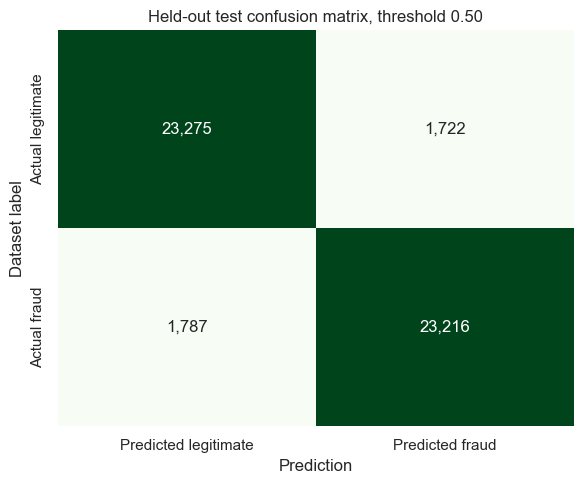

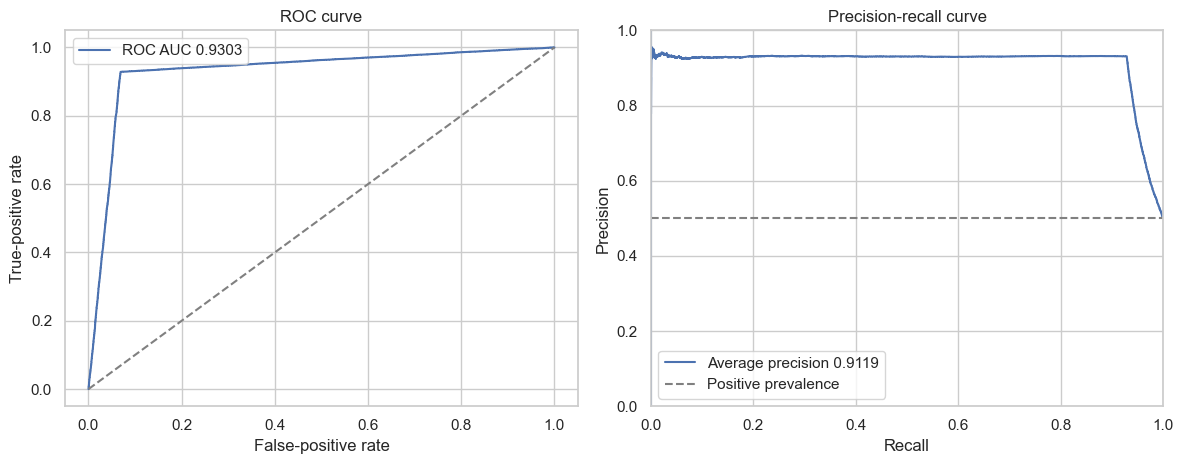

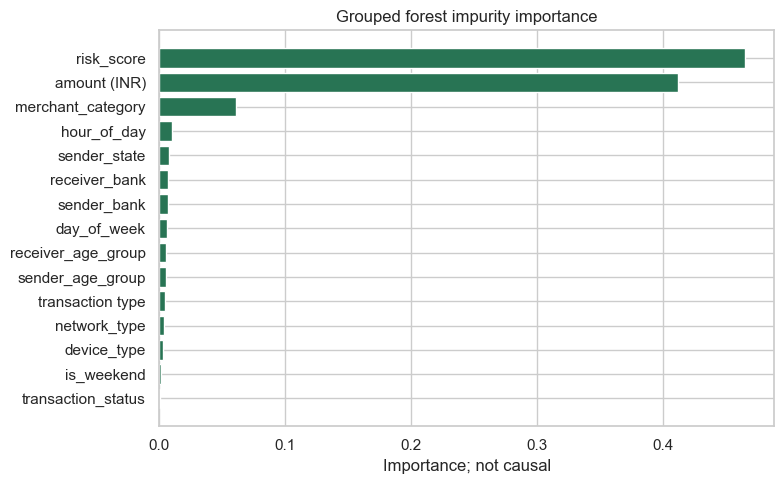

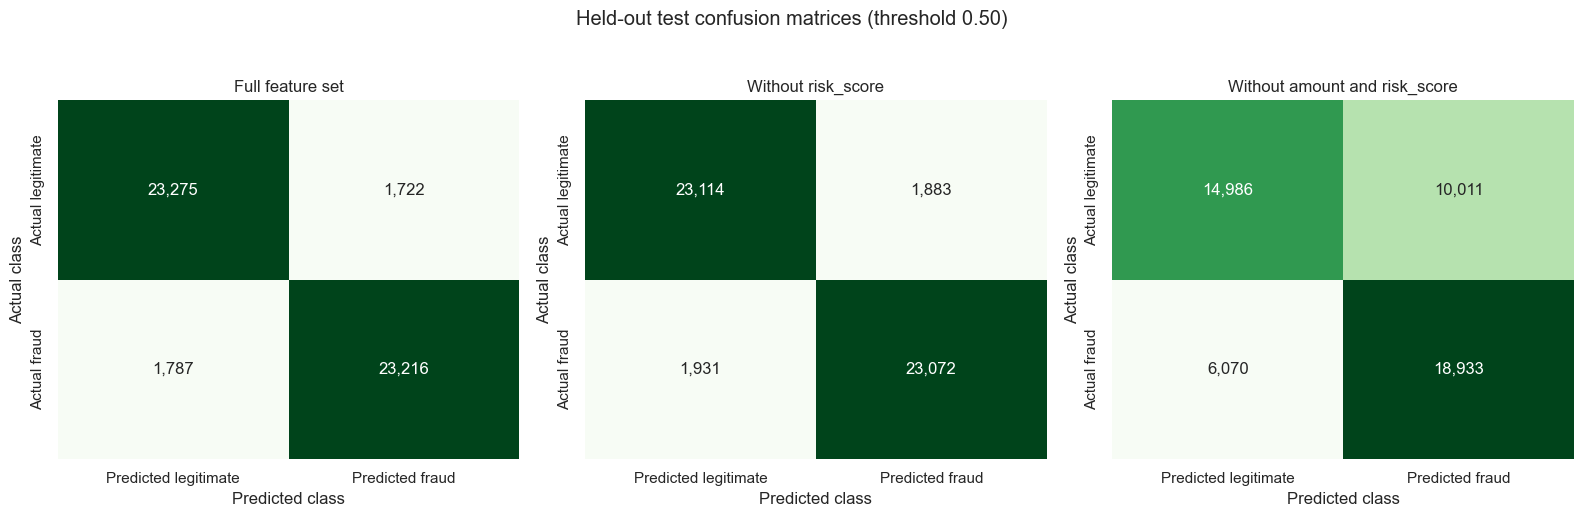

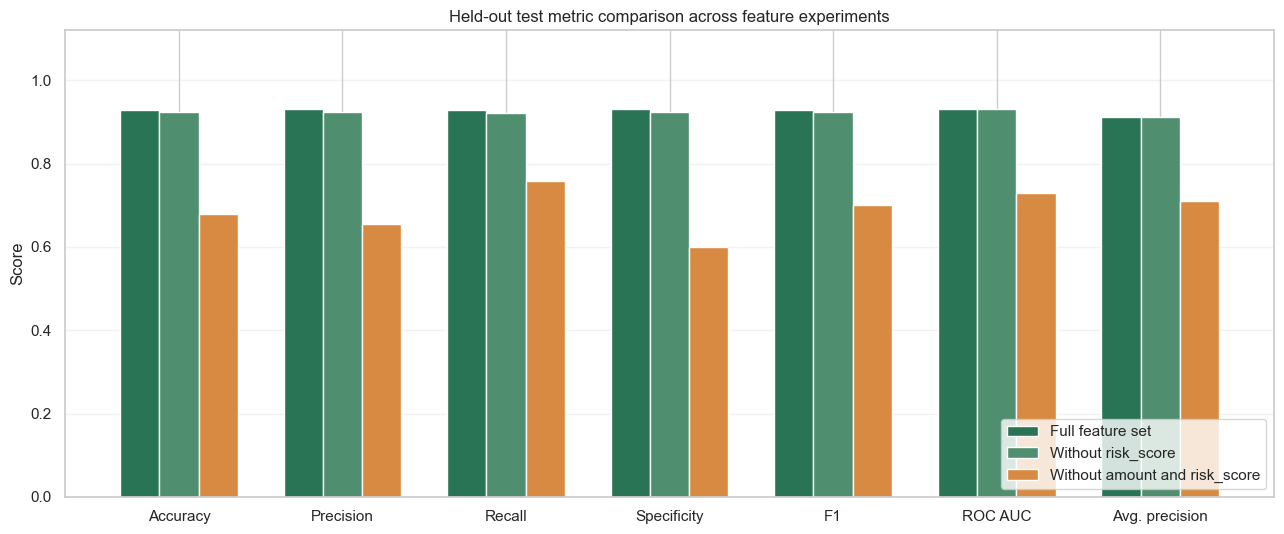

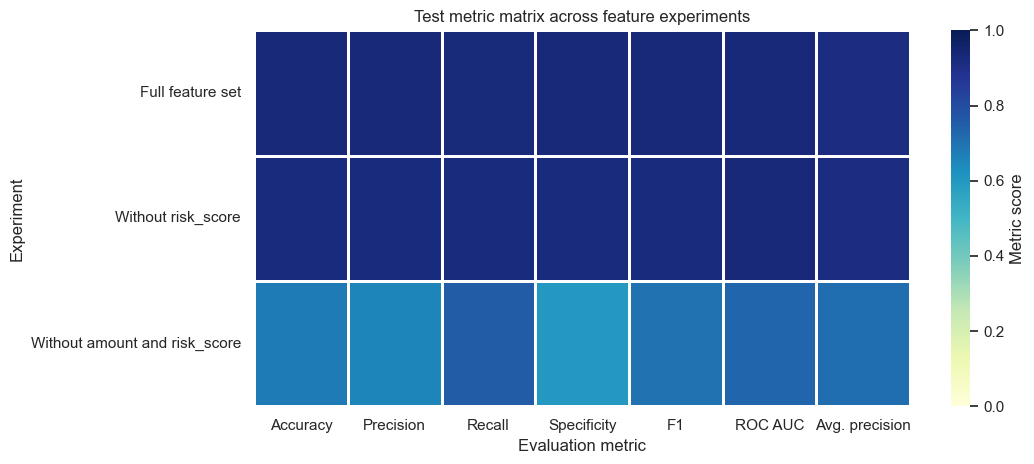

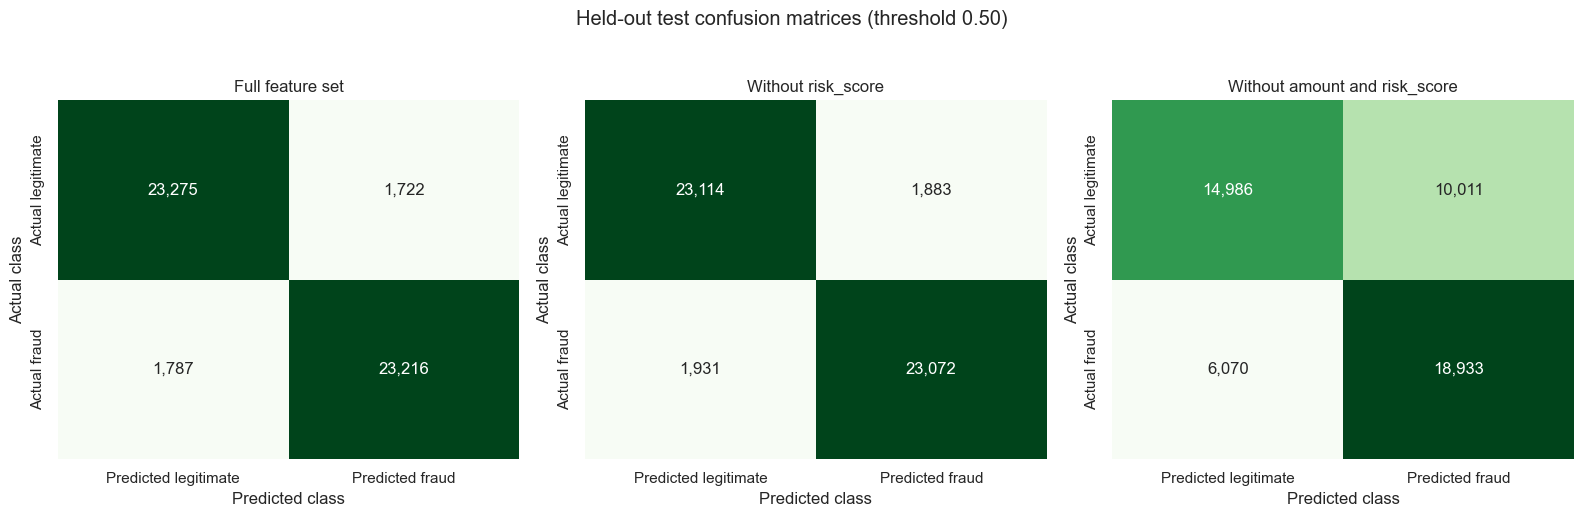

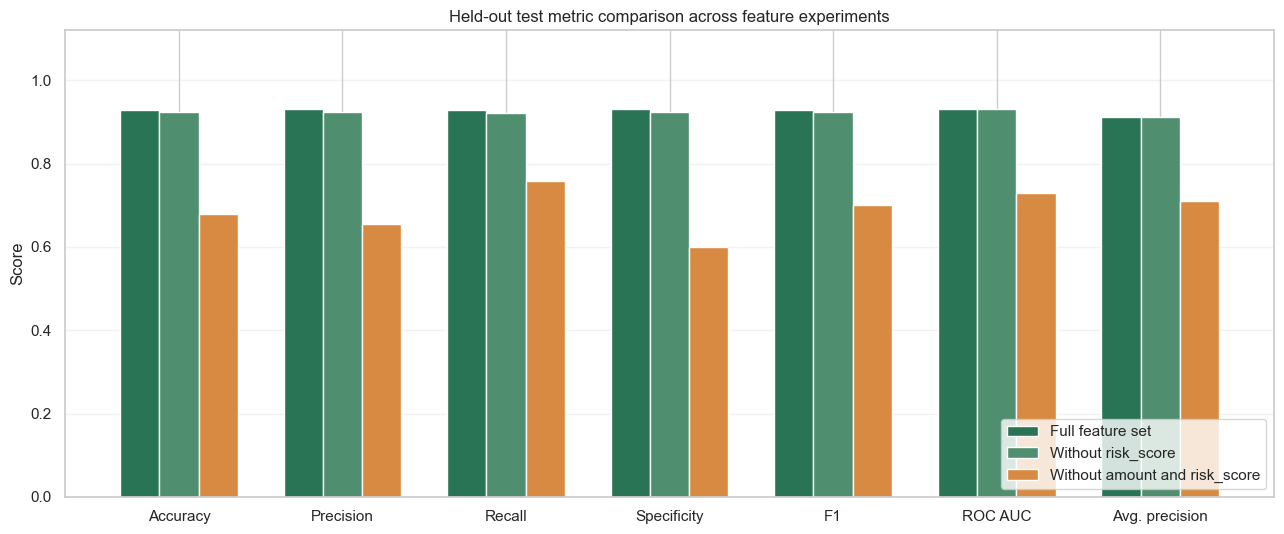

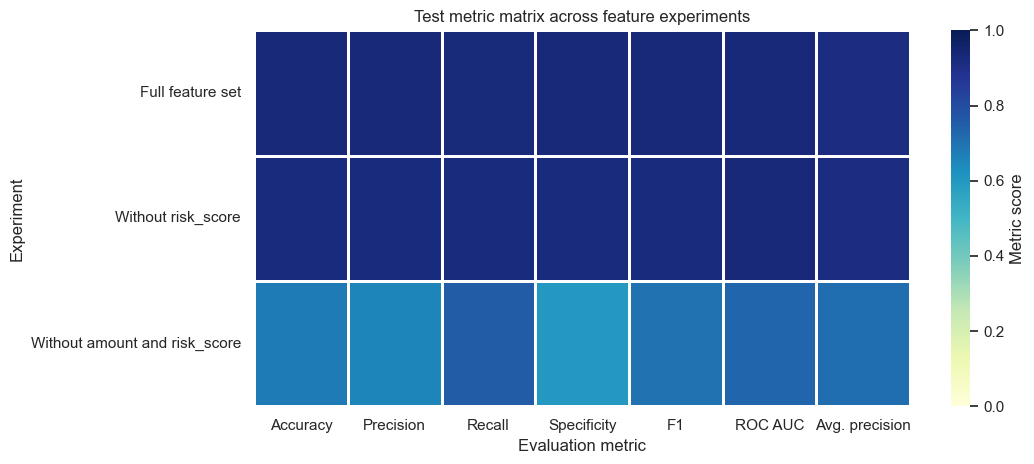

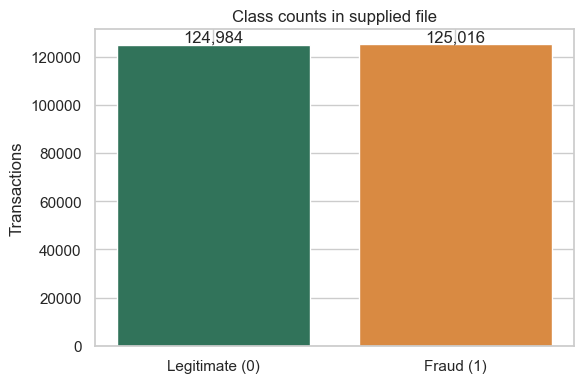

In [23]:
quality=pd.Series({'rows':len(df),'exact duplicate rows':int(df.duplicated().sum()),
'rows missing any non-target field':int(df.drop(columns=[target]).isna().any(axis=1).sum()),
'missing targets':int(df[target].isna().sum()),'fraud rows':int((df[target]==1).sum()),
'legitimate rows':int((df[target]==0).sum()),'fraud share':float((df[target]==1).mean())})
display(quality.to_frame('observed'))
counts=df[target].value_counts().reindex([0,1],fill_value=0)
fig,ax=plt.subplots(figsize=(6,4)); ax.bar(['Legitimate (0)','Fraud (1)'],counts.values,color=['#31735a','#d98a42'])
ax.set(title='Class counts in supplied file',ylabel='Transactions')
for i,v in enumerate(counts.values): ax.text(i,v,f'{v:,}',ha='center',va='bottom')
fig.tight_layout(); plt.show()

legitimate       fraud
amount (INR) count   124984.000  125016.000
             mean       445.967    2177.324
             median     307.000    1479.000
             std        789.794    2169.692
             min         10.000      14.000
             max      27541.000   42099.000
hour_of_day  count   124984.000  125016.000
             mean        14.482      14.880
             median      15.000      16.000
             std          5.241       5.127
             min          0.000       0.000
             max         23.000      23.000
is_weekend   count   124984.000  125016.000
             mean         0.286       0.285
             median       0.000       0.000
             std          0.452       0.451
             min          0.000       0.000
             max          1.000       1.000
risk_score   count   124984.000  125016.000
             mean       295.392    1163.063
             median     228.000     813.500
             std        395.530    1084.369
             min          6.000      23.500
             max      13865.500   21054.500

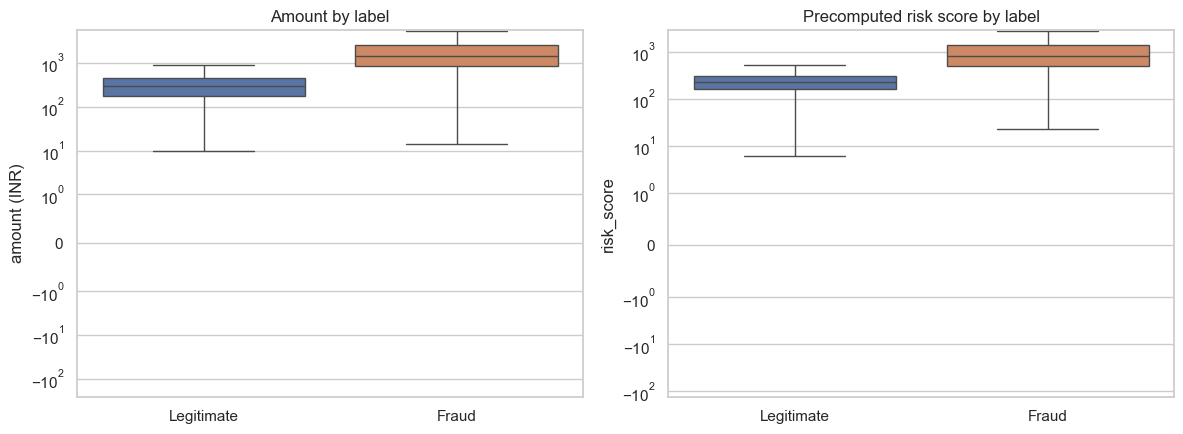

In [24]:
numeric=df.select_dtypes(include='number').columns.drop(target,errors='ignore').tolist()
summary=df.groupby(target)[numeric].agg(['count','mean','median','std','min','max']).T
summary.columns=['legitimate','fraud']; display(summary.round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,col,title in zip(axes,['amount (INR)','risk_score'],['Amount','Precomputed risk score']):
    sns.boxplot(data=df,x=target,y=col,showfliers=False,hue=target,legend=False,ax=ax)
    ax.set_yscale('symlog',linthresh=1); ax.set_xticks([0,1],['Legitimate','Fraud']); ax.set_title(title+' by label'); ax.set_xlabel('')
fig.tight_layout(); plt.show()

,amount (INR),risk_score,is_fraud
amount (INR),1.0000,0.9996,0.4684
risk_score,0.9996,1.0000,0.4693
is_fraud,0.4684,0.4693,1.0000


Univariate ROC AUC, amount (INR): 0.9287
Univariate ROC AUC, risk_score: 0.9296


,rows,fraud_rate,median_amount,median_risk
risk_score,,,,
"(5.999, 146.5]",25151,7.1%,101,119.5
"(146.5, 194.0]",25047,7.2%,190,171.0
"(194.0, 244.5]",24833,7.0%,283,218.5
"(244.5, 306.0]",25048,6.9%,393,274.0
"(306.0, 389.5]",24989,7.0%,536,344.0
"(389.5, 519.5]",25008,93.1%,745,447.0
"(519.5, 727.5]",24956,93.1%,"1,078",612.5
"(727.5, 1059.5]",24988,93.1%,"1,597",872.0
"(1059.5, 1691.05]",24980,93.1%,"2,472","1,309.0"


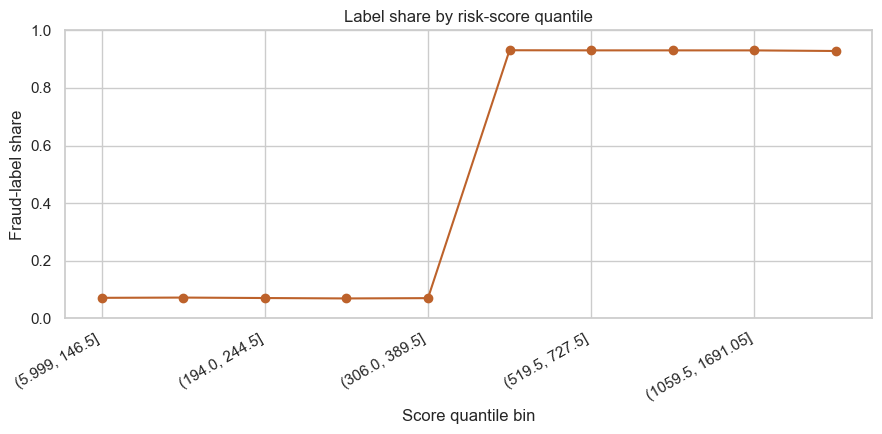

In [25]:
association=df[['amount (INR)','risk_score',target]].corr(); display(association.round(4))
for col in ['amount (INR)','risk_score']:
    print(f'Univariate ROC AUC, {col}: {roc_auc_score(df[target],df[col]):.4f}')
bins=pd.qcut(df.risk_score,10,duplicates='drop')
audit=df.groupby(bins,observed=True).agg(rows=(target,'size'),fraud_rate=(target,'mean'),
 median_amount=('amount (INR)','median'),median_risk=('risk_score','median'))
display(audit.style.format({'fraud_rate':'{:.1%}','median_amount':'{:,.0f}','median_risk':'{:,.1f}'}))
fig,ax=plt.subplots(figsize=(9,4.5)); audit.fraud_rate.plot(marker='o',ax=ax,color='#bd622b')
ax.set(title='Label share by risk-score quantile',xlabel='Score quantile bin',ylabel='Fraud-label share',ylim=(0,1))
plt.xticks(rotation=30,ha='right'); fig.tight_layout(); plt.show()


 transaction type (groups with n ≥ 500)


,rows,fraud_rate
transaction type,,
P2M,87660,50.1%
P2P,112445,50.0%
Bill Payment,37368,50.0%
Recharge,12527,49.1%



 merchant_category (groups with n ≥ 500)


,rows,fraud_rate
merchant_category,,
Education,7598,90.2%
Shopping,29872,72.0%
Utilities,22338,71.4%
Fuel,25063,65.5%
Grocery,49966,56.8%
Other,24828,48.9%
Food,37464,31.3%
Healthcare,12663,29.8%
Entertainment,20103,22.7%



 transaction_status (groups with n ≥ 500)


...

,rows,fraud_rate
network_type,,
3G,12471,50.9%
5G,62582,50.2%
WiFi,25134,50.1%
4G,149813,49.9%



 sender_bank (groups with n ≥ 500)


,rows,fraud_rate
sender_bank,,
PNB,24946,50.3%
HDFC,37485,50.3%
Yes Bank,24860,50.2%
ICICI,29769,50.0%
SBI,62693,50.0%
Axis,25042,50.0%
Kotak,20032,49.8%
IndusInd,25173,49.4%


Unparsed timestamps: 0 | range: 2024-01-01 00:05:10 to 2024-12-30 23:55:40


,rows,fraud_rate
month,,
2024-01-01 00:00:00,21221,49.8%
2024-02-01 00:00:00,19759,50.1%
2024-03-01 00:00:00,21234,49.8%
2024-04-01 00:00:00,20536,50.6%
2024-05-01 00:00:00,21333,50.0%
2024-06-01 00:00:00,20628,50.3%
2024-07-01 00:00:00,21207,49.9%
2024-08-01 00:00:00,21231,50.1%
2024-09-01 00:00:00,20597,49.7%


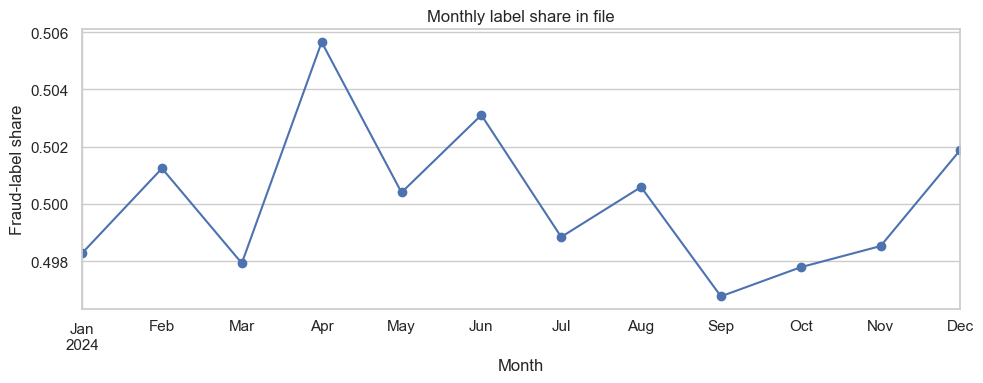

In [26]:
for col in ['transaction type','merchant_category','transaction_status','device_type','network_type','sender_bank']:
    if col not in df: continue
    tab=df.groupby(col,dropna=False).agg(rows=(target,'size'),fraud_rate=(target,'mean'))
    tab=tab[tab.rows>=500].sort_values('fraud_rate',ascending=False).head(12)
    print('\n',col,'(groups with n ≥ 500)'); display(tab.style.format({'fraud_rate':'{:.1%}'}))
time_df=df[['timestamp',target]].copy(); time_df.timestamp=pd.to_datetime(time_df.timestamp,errors='coerce')
print('Unparsed timestamps:',time_df.timestamp.isna().sum(),'| range:',time_df.timestamp.min(),'to',time_df.timestamp.max())
monthly=(time_df.dropna().assign(month=lambda x:x.timestamp.dt.to_period('M').dt.to_timestamp())
 .groupby('month').agg(rows=(target,'size'),fraud_rate=(target,'mean')))
display(monthly.head(12).style.format({'fraud_rate':'{:.1%}'}))
fig,ax=plt.subplots(figsize=(10,4)); monthly.fraud_rate.plot(marker='o',ax=ax)
ax.set(title='Monthly label share in file',xlabel='Month',ylabel='Fraud-label share'); fig.tight_layout()


In [27]:
import sklearn, joblib, flask
print('Python:',sys.version.split()[0],'| pandas:',pd.__version__,'| scikit-learn:',sklearn.__version__)
print('Matplotlib:',matplotlib.__version__,'| joblib:',joblib.__version__)
print('Seed: 42 | data MiB:',round(DATA_PATH.stat().st_size/1024**2,2))

Python: 3.12.0 | pandas: 2.3.2 | scikit-learn: 1.7.2
Matplotlib: 3.10.1 | joblib: 1.5.2
Seed: 42 | data MiB: 38.76


In [28]:
primary_metrics=train_model()
print('Selected:',primary_metrics['selected_model'])
print('Validation ROC AUC:',primary_metrics['validation_roc_auc'])
print(f"Rows: development {primary_metrics['train_rows']:,}; validation {primary_metrics['validation_rows']:,}; test {primary_metrics['test_rows']:,}")
print(f"File fraud-label share: {primary_metrics['fraud_rate']:.2%}")

Fitting logistic regression on 162,500 training rows…
  validation ROC AUC: 0.9239
Fitting random forest on 162,500 training rows…
  validation ROC AUC: 0.9269
Writing confusion-matrix plot…
Writing ROC plot…
Writing precision-recall plot…
Selected: random_forest
Validation ROC AUC: {'logistic_regression': 0.9238990540674736, 'random_forest': 0.926939780857626}
Rows: development 200,000; validation 37,500; test 50,000
File fraud-label share: 50.01%


In [29]:
metric_names=['accuracy','balanced_accuracy','precision','recall','specificity','f1','roc_auc','average_precision','matthews_corrcoef','brier_score']
display(pd.Series({k:primary_metrics[k] for k in metric_names},name='test result').to_frame().round(4))
print('Support:',primary_metrics['support'],'| errors:',primary_metrics['errors'])
display(pd.DataFrame(primary_metrics['confusion_matrix'],index=['Actual legitimate','Actual fraud'],
 columns=['Predicted legitimate','Predicted fraud']))
class_report=pd.DataFrame(primary_metrics['classification_report']).T
display(class_report.round(4))
cm=np.asarray(primary_metrics['confusion_matrix'])
fig,ax=plt.subplots(figsize=(6,5)); sns.heatmap(cm,annot=True,fmt=',d',cmap='Greens',cbar=False,
 xticklabels=['Predicted legitimate','Predicted fraud'],yticklabels=['Actual legitimate','Actual fraud'],ax=ax)
ax.set(title='Held-out test confusion matrix, threshold 0.50',xlabel='Prediction',ylabel='Dataset label')
fig.tight_layout(); plt.show()

,test result
accuracy,0.9298
balanced_accuracy,0.9298
precision,0.9309
recall,0.9285
specificity,0.9311
f1,0.9297
roc_auc,0.9303
average_precision,0.9119
matthews_corrcoef,0.8596
brier_score,0.0657


Support: {'legitimate': 24997, 'fraud': 25003} | errors: {'false_positives': 1722, 'false_negatives': 1787}


,Predicted legitimate,Predicted fraud
Actual legitimate,23275,1722
Actual fraud,1787,23216


,precision,recall,f1-score,support
legitimate,0.9287,0.9311,0.9299,24997.0000
fraud,0.9309,0.9285,0.9297,25003.0000
accuracy,0.9298,0.9298,0.9298,0.9298
macro avg,0.9298,0.9298,0.9298,50000.0000
weighted avg,0.9298,0.9298,0.9298,50000.0000


C:\Users\mohit\AppData\Local\Temp\ipykernel_5428\3217660766.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); plt.show()


In [30]:
bundle=load_model()
_,test_X,_,test_y=train_test_split(df[primary_metrics['features']],df[target].astype(int),
 test_size=.20,random_state=42,stratify=df[target].astype(int))
test_probability=bundle['model'].predict_proba(test_X)[:,1]
fpr,tpr,_=roc_curve(test_y,test_probability)
prec_curve,rec_curve,_=precision_recall_curve(test_y,test_probability)
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
axes[0].plot(fpr,tpr,label=f"ROC AUC {roc_auc_score(test_y,test_probability):.4f}"); axes[0].plot([0,1],[0,1],'--',color='grey')
axes[0].set(xlabel='False-positive rate',ylabel='True-positive rate',title='ROC curve'); axes[0].legend()
axes[1].plot(rec_curve,prec_curve,label=f"Average precision {average_precision_score(test_y,test_probability):.4f}")
axes[1].axhline(test_y.mean(),ls='--',color='grey',label='Positive prevalence')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision-recall curve',xlim=(0,1),ylim=(0,1)); axes[1].legend()
fig.tight_layout(); plt.show()

C:\Users\mohit\AppData\Local\Temp\ipykernel_5428\2990327858.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); plt.show()


In [31]:
importance_path=OUTPUT_DIR/'feature_importance.csv'
if importance_path.exists():
    importance=pd.read_csv(importance_path).sort_values('importance',ascending=False)
    display(importance)
    fig,ax=plt.subplots(figsize=(8,5)); top=importance.head(15).sort_values('importance')
    ax.barh(top.source_feature,top.importance,color='#287454')
    ax.set(title='Grouped forest impurity importance',xlabel='Importance; not causal')
    fig.tight_layout(); plt.show()
else: print('Selected estimator has no forest impurity-importance artifact.')

,source_feature,importance
0,risk_score,0.464686
1,amount (INR),0.412108
2,merchant_category,0.060875
3,hour_of_day,0.009812
4,sender_state,0.007839
5,receiver_bank,0.007082
6,sender_bank,0.006934
7,day_of_week,0.006505
8,receiver_age_group,0.005449
9,sender_age_group,0.005218


C:\Users\mohit\AppData\Local\Temp\ipykernel_5428\2609771163.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); plt.show()


In [32]:
ABLATION_ROOT=OUTPUT_DIR/'feature_ablations'
without_risk=train_model(excluded_features=['risk_score'], model_path=None,
 artifact_dir=ABLATION_ROOT/'without_risk_score')
print('Without risk_score:',without_risk['selected_model'],
      f"ROC AUC={without_risk['roc_auc']:.4f}",f"F1={without_risk['f1']:.4f}")

Fitting logistic regression on 162,500 training rows…
  validation ROC AUC: 0.9238
Fitting random forest on 162,500 training rows…
  validation ROC AUC: 0.9265
Writing confusion-matrix plot…
Writing ROC plot…
Writing precision-recall plot…
Without risk_score: random_forest ROC AUC=0.9306 F1=0.9237


In [33]:
without_amount_and_risk=train_model(excluded_features=['amount (INR)','risk_score'], model_path=None,
 artifact_dir=ABLATION_ROOT/'without_amount_and_risk_score')
print('Without amount and risk_score:',without_amount_and_risk['selected_model'],
      f"ROC AUC={without_amount_and_risk['roc_auc']:.4f}",f"F1={without_amount_and_risk['f1']:.4f}")

Fitting logistic regression on 162,500 training rows…
  validation ROC AUC: 0.7282
Fitting random forest on 162,500 training rows…
  validation ROC AUC: 0.7277
Writing confusion-matrix plot…
Writing ROC plot…
Writing precision-recall plot…
Without amount and risk_score: logistic_regression ROC AUC=0.7297 F1=0.7019


In [34]:
experiments=[('Full features',primary_metrics),('Without risk_score',without_risk),
             ('Without amount and risk_score',without_amount_and_risk)]
comparison=pd.DataFrame([{
 'experiment':name,'selected model':m['selected_model'],
 'validation ROC AUC':m['validation_roc_auc'][m['selected_model']],
 'test accuracy':m['accuracy'],'test precision':m['precision'],'test recall':m['recall'],
 'test specificity':m['specificity'],'test F1':m['f1'],'test ROC AUC':m['roc_auc'],
 'test average precision':m['average_precision'],'false positives':m['errors']['false_positives'],
 'false negatives':m['errors']['false_negatives']} for name,m in experiments])
display(comparison.set_index('experiment').style.format(precision=4))
comparison.to_csv(OUTPUT_DIR/'experiment_comparison.csv',index=False)

,selected model,validation ROC AUC,test accuracy,test precision,test recall,test specificity,test F1,test ROC AUC,test average precision,false positives,false negatives
experiment,,,,,,,,,,,
Full features,random_forest,0.9269,0.9298,0.9309,0.9285,0.9311,0.9297,0.9303,0.9119,1722,1787
Without risk_score,random_forest,0.9265,0.9237,0.9245,0.9228,0.9247,0.9237,0.9306,0.9132,1883,1931
Without amount and risk_score,logistic_regression,0.7282,0.6784,0.6541,0.7572,0.5995,0.7019,0.7297,0.7103,10011,6070


In [35]:
# Recreate the comparison figures directly in this notebook from saved evaluation metrics.
# Run this cell after the full model and both feature-ablation experiments have completed.
import json
from IPython.display import display

report_dirs = [
    ('Full feature set', OUTPUT_DIR),
    ('Without risk_score', OUTPUT_DIR / 'feature_ablations' / 'without_risk_score'),
    ('Without amount and risk_score', OUTPUT_DIR / 'feature_ablations' / 'without_amount_and_risk_score'),
]
all_results = [(name, json.loads((folder / 'metrics.json').read_text(encoding='utf-8')))
               for name, folder in report_dirs]

# Confusion matrices: values are generated from the numeric matrices in metrics.json.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, result) in zip(axes, all_results):
    matrix = np.asarray(result['confusion_matrix'])
    sns.heatmap(matrix, annot=True, fmt=',d', cmap='Greens', cbar=False, ax=ax,
                xticklabels=['Predicted legitimate', 'Predicted fraud'],
                yticklabels=['Actual legitimate', 'Actual fraud'])
    ax.set_title(name)
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
fig.suptitle('Held-out test confusion matrices (threshold 0.50)', y=1.03)
fig.tight_layout()
plt.show()

# Compare model quality metrics across the same held-out test experiments.
metric_columns = ['accuracy', 'precision', 'recall', 'specificity', 'f1', 'roc_auc', 'average_precision']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC AUC', 'Avg. precision']
metric_values = np.array([[result[key] for key in metric_columns] for _, result in all_results])
fig, ax = plt.subplots(figsize=(13, 5.5))
bar_width = 0.24
x = np.arange(len(metric_labels))
colors = ['#287454', '#508e70', '#d98a42']
for i, ((name, _), values) in enumerate(zip(all_results, metric_values)):
    bars = ax.bar(x + (i - 1) * bar_width, values, bar_width, label=name, color=colors[i])
ax.set_xticks(x, metric_labels)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score')
ax.set_title('Held-out test metric comparison across feature experiments')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=.25)
fig.tight_layout()
plt.show()

# A matrix-style heatmap gives a visual comparison without displaying a score table.
fig, ax = plt.subplots(figsize=(11, 4.8))
metric_matrix = pd.DataFrame(metric_values, index=[name for name, _ in all_results],
                             columns=metric_labels)
sns.heatmap(metric_matrix, annot=False, cmap='YlGnBu', vmin=0, vmax=1,
            linewidths=1, linecolor='white', cbar_kws={'label': 'Metric score'}, ax=ax)
ax.set_title('Test metric matrix across feature experiments')
ax.set_xlabel('Evaluation metric')
ax.set_ylabel('Experiment')
fig.tight_layout()
plt.show()

# Save the detailed numeric report for reproducibility, without printing it as a table here.
class_frames = []
for name, result in all_results:
    report = pd.DataFrame(result['classification_report']).T
    report.index.name = 'class_or_average'
    report.insert(0, 'experiment', name)
    class_frames.append(report.reset_index())
all_class_reports = pd.concat(class_frames, ignore_index=True)
all_class_reports.to_csv(OUTPUT_DIR / 'all_classification_reports.csv', index=False)
print('All graphical plots are displayed inline in this notebook.')


C:\Users\mohit\AppData\Local\Temp\ipykernel_5428\2783561376.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\mohit\AppData\Local\Temp\ipykernel_5428\2783561376.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\mohit\AppData\Local\Temp\ipykernel_5428\2783561376.py:57: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


All graphical plots are displayed inline in this notebook.
